In [1]:

from PIL import Image
import pandas as pd
import os

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

In [2]:
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


In [3]:
path = '/content/gdrive/MyDrive/Colab Notebooks/Fashion_Peaks'
os.chdir(path)

In [4]:
class SpectraClassificationDataset(Dataset):
    def __init__(self, csv_file, root_dir, transform=None):
        self.labels_df = pd.read_csv(csv_file)
        self.root_dir = root_dir
        self.transform = transform

    def __len__(self):
        return len(self.labels_df) # ← acá están tus 2000 entradas


    def __getitem__(self, idx):
        img_path = os.path.join(self.root_dir, self.labels_df.iloc[idx, 0])
        image = Image.open(img_path).convert('L')  # Escala de grises

        area = self.labels_df.iloc[idx, 1]

        # Esta es la línea que incorporás:
        clase = min(39, int((area - 1) // 500))

        label = torch.tensor(clase, dtype=torch.long)

        if self.transform:
            image = self.transform(image)

        return image, label


In [5]:
# Transformación (opcional: normalizar a [0,1])
transform = transforms.Compose([
    transforms.ToTensor(),  # convierte a [C,H,W] con valores entre 0 y 1
])

# Crear dataset y dataloader
dataset = SpectraClassificationDataset(csv_file="imagenes_entrenamiento/labels.csv",
                                       root_dir="imagenes_entrenamiento",
                                       transform=transform)

# Tenemos 40 categorias -bins- y hemos creado 2000, para que haya aprox. 50 de cada uno.
# dataloader = DataLoader(dataset, batch_size=2000, shuffle=True)
dataloader = DataLoader(dataset, batch_size=32, shuffle=True)

# Prueba de un batch
for images, labels in dataloader:
    print(images.shape)  # [32, 1, 60, 30] si las imágenes son 30x60
    print(labels)
    break


torch.Size([32, 1, 49, 24])
tensor([ 0,  1, 10,  0, 11,  0,  1,  1,  0, 33,  2,  0,  1,  0,  0,  3, 22,  1,
         1,  1,  0,  8,  1,  0,  1,  1,  3, 18,  1,  0,  0,  4])


In [6]:
print(len(images))

32


In [6]:
def clase_a_valor(clase):
    return clase * 500 + 250


In [7]:
for images, labels in dataloader:
    print("Clases:", labels.tolist())
    valores_area = [clase_a_valor(clase.item()) for clase in labels]
    print("Áreas estimadas:", valores_area)
    break


Clases: [1, 3, 1, 0, 0, 0, 0, 0, 4, 1, 0, 0, 18, 19, 1, 4, 0, 1, 3, 0, 1, 3, 1, 2, 1, 0, 2, 3, 1, 6, 0, 0]
Áreas estimadas: [750, 1750, 750, 250, 250, 250, 250, 250, 2250, 750, 250, 250, 9250, 9750, 750, 2250, 250, 750, 1750, 250, 750, 1750, 750, 1250, 750, 250, 1250, 1750, 750, 3250, 250, 250]


Supuestos clave:

    Imágenes en escala de grises de tamaño fijo, por ejemplo 1×46×23 (como el ejemplo que mostraste).

    40 clases (n_classes = 40).

    Ya tenés el dataloader funcionando.

In [8]:
#import torch
#import torch.nn as nn
#import torch.nn.functional as F

class SpectraCNN(nn.Module):
    def __init__(self, n_classes=41):
        super(SpectraCNN, self).__init__()

        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)  # 1 canal → 16
        self.pool1 = nn.MaxPool2d(2, 2)  # reduce tamaño a la mitad

        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.pool2 = nn.MaxPool2d(2, 2)

        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.pool3 = nn.AdaptiveAvgPool2d((1, 1))  # produce [64, 1, 1]

        self.fc1 = nn.Linear(64, 128)
        self.dropout = nn.Dropout(0.4)
        self.fc2 = nn.Linear(128, n_classes)  # salida final

    def forward(self, x):
        x = F.relu(self.conv1(x))  # [B,16,H,W]
        x = self.pool1(x)

        x = F.relu(self.conv2(x))  # [B,32,H/2,W/2]
        x = self.pool2(x)

        x = F.relu(self.conv3(x))  # [B,64,H/4,W/4]
        x = self.pool3(x)          # [B,64,1,1]
        x = x.view(x.size(0), -1)  # flatten a [B,64]

        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x


In [9]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# device = torch.device("cpu")

In [10]:
model = SpectraCNN(n_classes=41).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

"""
   lr ¿Qué valor usar?
    0.001 (1e-3) es un valor inicial muy común para Adam (y el que estamos usando ahora).
    Si ves mucha inestabilidad, probar con 1e-4 (0.0001) para que el aprendizaje sea más fino.
    También se puede usar tasa de aprendizaje variable (scheduler), para más adelante.
"""

train_losses = []
train_accuracies = []

for epoch in range(60):  # cambie 50 por 10 para ver los graficos
    model.train()
    running_loss = 0.0

    for images, labels in dataloader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * images.size(0)

    epoch_loss = running_loss / len(dataloader.dataset)

    # Evaluación al final de la época
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in dataloader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            preds = torch.argmax(outputs, dim=1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)

    accuracy = correct / total
    train_losses.append(epoch_loss)
    train_accuracies.append(accuracy)

    print(f"Epoch {epoch+1}, Loss: {epoch_loss:.4f}, Accuracy: {accuracy*100:.2f}%")


Epoch 1, Loss: 2.3927, Accuracy: 37.35%
Epoch 2, Loss: 1.9665, Accuracy: 37.35%
Epoch 3, Loss: 1.8793, Accuracy: 37.35%
Epoch 4, Loss: 1.7446, Accuracy: 37.90%
Epoch 5, Loss: 1.5213, Accuracy: 40.75%
Epoch 6, Loss: 1.3191, Accuracy: 53.70%
Epoch 7, Loss: 1.1269, Accuracy: 54.70%
Epoch 8, Loss: 1.0220, Accuracy: 75.10%
Epoch 9, Loss: 0.9091, Accuracy: 70.65%
Epoch 10, Loss: 0.8512, Accuracy: 75.50%
Epoch 11, Loss: 0.8206, Accuracy: 66.90%
Epoch 12, Loss: 0.8076, Accuracy: 80.90%
Epoch 13, Loss: 0.7583, Accuracy: 72.40%
Epoch 14, Loss: 0.7110, Accuracy: 80.55%
Epoch 15, Loss: 0.6870, Accuracy: 81.15%
Epoch 16, Loss: 0.6741, Accuracy: 80.40%
Epoch 17, Loss: 0.6351, Accuracy: 80.60%
Epoch 18, Loss: 0.6357, Accuracy: 72.85%
Epoch 19, Loss: 0.6179, Accuracy: 82.00%
Epoch 20, Loss: 0.6954, Accuracy: 75.50%
Epoch 21, Loss: 0.6446, Accuracy: 80.75%
Epoch 22, Loss: 0.5985, Accuracy: 82.75%
Epoch 23, Loss: 0.6095, Accuracy: 81.80%
Epoch 24, Loss: 0.5682, Accuracy: 83.25%
Epoch 25, Loss: 0.5922, A


## ✅ 1. Guardar y graficar pérdida y accuracy por época

### 🔹 Durante el entrenamiento, agregá esto:

Antes del bucle de entrenamiento:

Dentro del bucle `for epoch in range(...):`, después del cálculo de `epoch_loss`, agregamos:

In [11]:
# Calcular accuracy en esta época
model.eval()
correct = 0
total = 0
with torch.no_grad():
    for images, labels in dataloader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        preds = torch.argmax(outputs, dim=1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
accuracy = correct / total

train_losses.append(epoch_loss)
train_accuracies.append(accuracy)

print(f"Epoch {epoch+1}, Loss: {epoch_loss:.4f}, Accuracy: {accuracy*100:.2f}%")


Epoch 60, Loss: 0.4655, Accuracy: 86.45%


In [12]:
# Salvar la red neuronal
torch.save(model.state_dict(), "modelo_entrenado.pth")
print("Modelo guardado en modelo_entrenado.pth")


Modelo guardado en modelo_entrenado.pth


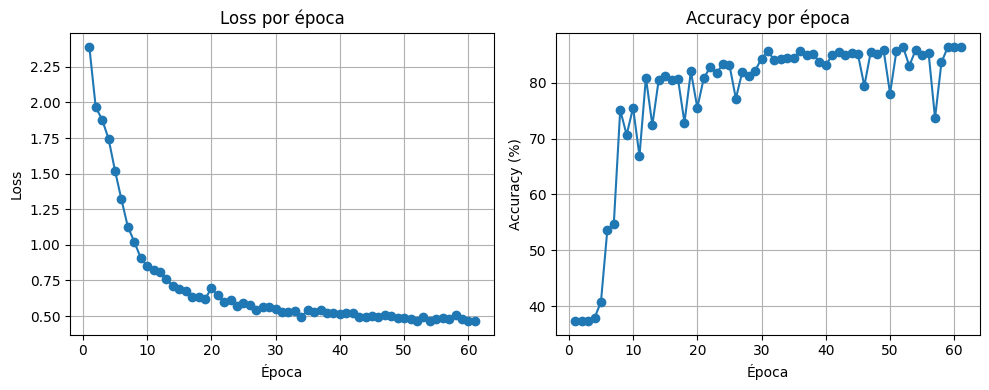

In [13]:
### 🔹 Luego de entrenar, graficá:

import matplotlib.pyplot as plt

epochs = list(range(1, len(train_losses)+1))

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs, train_losses, marker='o')
plt.title("Loss por época")
plt.xlabel("Época")
plt.ylabel("Loss")
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(epochs, [a*100 for a in train_accuracies], marker='o')
plt.title("Accuracy por época")
plt.xlabel("Época")
plt.ylabel("Accuracy (%)")

plt.tight_layout()
plt.grid()
plt.show()

In [14]:
def clase_a_valor(clase):
    return clase * 500 + 250

model.eval()
errores = []

with torch.no_grad():
    for images, labels in dataloader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        preds = torch.argmax(outputs, dim=1)

        # Convertimos clases a valores reales de área
        reales = [clase_a_valor(c.item()) for c in labels]
        predichos = [clase_a_valor(c.item()) for c in preds]

        errores.extend([abs(r - p) for r, p in zip(reales, predichos)])

# Calcular MAE
mae = sum(errores) / len(errores)
print(f"Error absoluto medio (MAE): {mae:.2f} unidades de área")

Error absoluto medio (MAE): 86.00 unidades de área
